In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from sklearn.svm import SVC

In [2]:
np.random.seed(2727)
n_per_class = 100
r = 0.1
capacity = 10 / 200
noise_scale = 0.1
grid_step = 0.04
plot_limit = 4.0
output_dir = Path(".")
output_dir.mkdir(exist_ok=True)

In [3]:
theta = np.linspace(0, 3, n_per_class)
a = 1.0
b = 0.5
radius = a * np.exp(b * theta)
x1_positive = radius * np.cos(theta * np.pi)
x2_positive = radius * np.sin(theta * np.pi)
x1_negative = -radius * np.cos(theta * np.pi)
x2_negative = -radius * np.sin(theta * np.pi)
x1 = np.concatenate([x1_positive, x1_negative])
x2 = np.concatenate([x2_positive, x2_negative])
noise = np.random.normal(scale=noise_scale, size=(2 * n_per_class, 2))
x = np.column_stack([x2, x1]) + noise
y = np.concatenate([np.ones(n_per_class, dtype=int), -np.ones(n_per_class, dtype=int)])

In [4]:
# Gaussian kernel uses the one-half factor in the slide formula.
radial_basis = np.linalg.inv(np.cov(x, rowvar=False)) / r ** 2

def anisotropic_gaussian(x_left, x_right):
    difference = x_left[:, None, :] - x_right[None, :, :]
    distance = np.einsum('...i,ij,...j->...', difference, radial_basis, difference)
    return np.exp(-0.5 * distance)
model = SVC(C=capacity, kernel=anisotropic_gaussian)
model.fit(x, y)
print(f'Training accuracy: {model.score(x, y):.3f}')
print(f'Support vectors: {len(model.support_)}')

Training accuracy: 1.000
Support vectors: 200


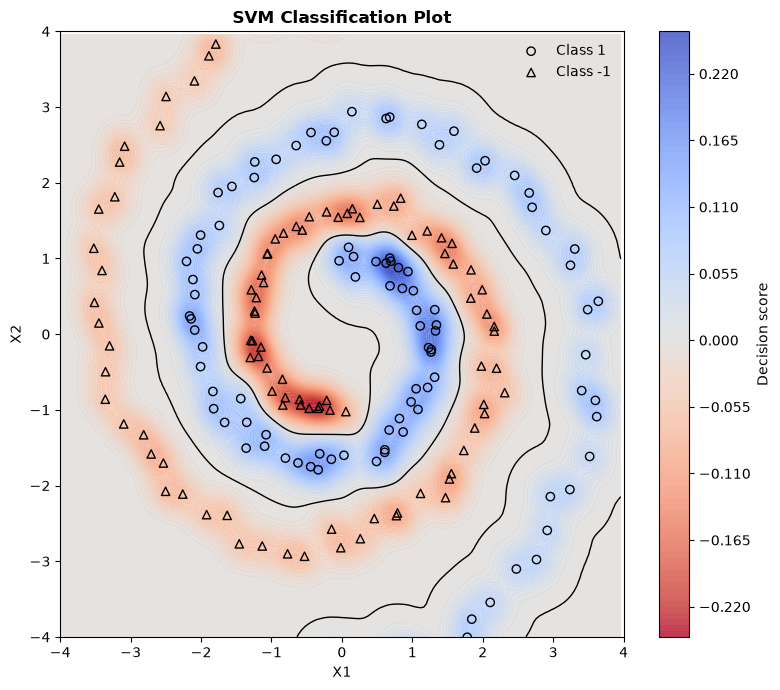

In [5]:
xx, yy = np.meshgrid(np.arange(-plot_limit, plot_limit, grid_step), np.arange(-plot_limit, plot_limit, grid_step))
score = model.decision_function(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
plt.figure(figsize=(8, 7))
filled_contour = plt.contourf(xx, yy, score, levels=100, cmap='coolwarm_r', alpha=0.8)
plt.contour(xx, yy, score, levels=[0], colors='black', linewidths=1)
plt.scatter(x[y == 1, 0], x[y == 1, 1], facecolors='none', edgecolors='black', marker='o', label='Class 1')
plt.scatter(x[y == -1, 0], x[y == -1, 1], facecolors='none', edgecolors='black', marker='^', label='Class -1')
plt.xlim(-plot_limit, plot_limit)
plt.ylim(-plot_limit, plot_limit)
plt.xlabel('X1')
plt.ylabel('X2')
plt.title('SVM Classification Plot', fontweight='bold')
plt.legend(frameon=False)
plt.colorbar(filled_contour, label='Decision score')
plt.tight_layout()
plt.savefig(output_dir / '20260915 MVAsvmSpiral.png', transparent=True, dpi=300)
plt.show()